## 2.2 全连接神经网络（MLP）

前面几个 cell 是自己写的 MLP 小练习（1→8→1、手动看每层梯度），下面是正式实验：在与 2.1 完全相同的数据上训练 MLP，并与线性模型在相同训练配置下对比。

结果表格、对比图与分析见 `2.2_实验报告.md`。

In [13]:
# 2.2-(1) 数据：与 2.1 完全一致（同样的 SEED），保证两个模型面对同一份数据
import numpy as np

# 注意：本机先 import pandas 再 import torch 会报 DLL 初始化失败，所以 torch 放在 pandas 之前
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time
import pandas as pd

from sklearn.datasets import make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

X, y = make_friedman1(
    n_samples=1500,
    n_features=10,
    noise=1.0,
    random_state=42
)

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=SEED)

x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train.reshape(-1, 1))


def to_tensor(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32)


X_train_t = to_tensor(x_scaler.transform(X_train))
X_val_t = to_tensor(x_scaler.transform(X_val))
X_test_t = to_tensor(x_scaler.transform(X_test))

y_train_t = to_tensor(y_scaler.transform(y_train.reshape(-1, 1)))
y_val_t = to_tensor(y_scaler.transform(y_val.reshape(-1, 1)))
y_test_t = to_tensor(y_scaler.transform(y_test.reshape(-1, 1)))

print("train %d / val %d / test %d，特征数 %d"
      % (len(X_train), len(X_val), len(X_test), X.shape[1]))
print("y std = %.4f" % y_test.std())


train 900 / val 300 / test 300，特征数 10
y std = 4.8284


In [14]:
# 2.2-(2) 两个模型：线性模型（对照）与 MLP（10 → 64 → 32 → 1，隐藏层 ReLU，输出层不加激活）
class LinearRegressor(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.linear = nn.Linear(in_features, 1)

    def forward(self, x):
        return self.linear(x)


class MLPRegressor(nn.Module):
    def __init__(self, in_features, hidden1=64, hidden2=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.net(x)


lin_model = LinearRegressor(X.shape[1])
mlp_model = MLPRegressor(X.shape[1])

print("---- 线性模型 ----")
print(lin_model)
print("参数量: %d" % sum(p.numel() for p in lin_model.parameters()))

print("\n---- MLP ----")
print(mlp_model)
print("参数量: %d" % sum(p.numel() for p in mlp_model.parameters()))


---- 线性模型 ----
LinearRegressor(
  (linear): Linear(in_features=10, out_features=1, bias=True)
)
参数量: 11

---- MLP ----
MLPRegressor(
  (net): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
参数量: 2817


In [15]:
# 2.2-(3) 两个模型用完全相同的训练配置（数据、batch、优化器、lr、epochs、种子都一致）
BATCH_SIZE = 64
EPOCHS = 200
LR = 0.01


def make_loader():
    return DataLoader(TensorDataset(X_train_t, y_train_t),
                      batch_size=BATCH_SIZE, shuffle=True)


def train_model(model, epochs=EPOCHS, lr=LR, log_every=50):
    """返回 (训练耗时, 训练集loss曲线, 验证集loss曲线, 最优验证MSE)"""
    torch.manual_seed(SEED)
    loader = make_loader()
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_hist, val_hist = [], []
    best_val, best_state = float("inf"), None

    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        running = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(X_train_t)

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_val_t), y_val_t).item()

        train_hist.append(train_loss)
        val_hist.append(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        if log_every and (epoch + 1) % log_every == 0:
            print("  epoch [%3d/%d] train MSE %.4f  val MSE %.4f"
                  % (epoch + 1, epochs, train_loss, val_loss))

    model.load_state_dict(best_state)
    elapsed = time.time() - t0
    model.eval()
    return elapsed, train_hist, val_hist, best_val


def predict_original(model, X_t):
    with torch.no_grad():
        return y_scaler.inverse_transform(model(X_t).numpy()).ravel()


def regression_metrics(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    return dict(model=name, MSE=mse, RMSE=mse ** 0.5,
                MAE=mean_absolute_error(y_true, y_pred),
                R2=r2_score(y_true, y_pred))


print("训练线性模型…")
lin_time, lin_train_hist, lin_val_hist, lin_best_val = train_model(lin_model)

print("\n训练 MLP…")
mlp_time, mlp_train_hist, mlp_val_hist, mlp_best_val = train_model(mlp_model)

print("\n训练完成：")
print("  线性模型 最优验证 MSE（标准化空间）= %.4f，耗时 %.2f 秒" % (lin_best_val, lin_time))
print("  MLP      最优验证 MSE（标准化空间）= %.4f，耗时 %.2f 秒" % (mlp_best_val, mlp_time))


训练线性模型…
  epoch [ 50/200] train MSE 0.2792  val MSE 0.2663
  epoch [100/200] train MSE 0.2796  val MSE 0.2693
  epoch [150/200] train MSE 0.2820  val MSE 0.2709
  epoch [200/200] train MSE 0.2807  val MSE 0.2672

训练 MLP…
  epoch [ 50/200] train MSE 0.0253  val MSE 0.0843
  epoch [100/200] train MSE 0.0147  val MSE 0.0895
  epoch [150/200] train MSE 0.0200  val MSE 0.0990
  epoch [200/200] train MSE 0.0082  val MSE 0.0976

训练完成：
  线性模型 最优验证 MSE（标准化空间）= 0.2635，耗时 12.71 秒
  MLP      最优验证 MSE（标准化空间）= 0.0699，耗时 19.97 秒


In [16]:
# 2.2-(4) 把两个模型的结果汇总成一张对比表
lin_pred_train, lin_pred_test = predict_original(lin_model, X_train_t), predict_original(lin_model, X_test_t)
mlp_pred_train, mlp_pred_test = predict_original(mlp_model, X_train_t), predict_original(mlp_model, X_test_t)

lin_m = regression_metrics(y_test, lin_pred_test, "线性模型")
mlp_m = regression_metrics(y_test, mlp_pred_test, "MLP")

lin_train_m = regression_metrics(y_train, lin_pred_train, "线性模型")
mlp_train_m = regression_metrics(y_train, mlp_pred_train, "MLP")

rows = []
for m, tr, t_hist, v_hist, el, tag in [
    (lin_m, lin_train_m, lin_train_hist, lin_val_hist, lin_time, "Linear"),
    (mlp_m, mlp_train_m, mlp_train_hist, mlp_val_hist, mlp_time, "MLP(64-32)"),
]:
    model_obj = lin_model if tag == "Linear" else mlp_model
    rows.append({
        "模型": tag,
        "参数量": sum(p.numel() for p in model_obj.parameters()),
        "隐藏层": "无" if tag == "Linear" else "2 层 (64, 32) + ReLU",
        "训练耗时(s)": round(el, 2),
        "训练集 RMSE": round(tr["RMSE"], 4),
        "测试集 MSE": round(m["MSE"], 4),
        "测试集 RMSE": round(m["RMSE"], 4),
        "测试集 MAE": round(m["MAE"], 4),
        "测试集 R2": round(m["R2"], 4),
        "最终训练MSE(标准化)": round(t_hist[-1], 4),
        "最优验证MSE(标准化)": round(min(v_hist), 4),
    })

compare_table = pd.DataFrame(rows)
print("================ 线性模型 vs 全连接神经网络 对比表 ================")
print(compare_table.to_string(index=False))

print("\n测试集 RMSE：%.4f -> %.4f（降低 %.2f%%）"
      % (lin_m["RMSE"], mlp_m["RMSE"],
         100 * (lin_m["RMSE"] - mlp_m["RMSE"]) / lin_m["RMSE"]))
print("测试集 R2：  %.4f -> %.4f" % (lin_m["R2"], mlp_m["R2"]))
print("参数量：%d -> %d（约 %.1f 倍）"
      % (sum(p.numel() for p in lin_model.parameters()),
         sum(p.numel() for p in mlp_model.parameters()),
         sum(p.numel() for p in mlp_model.parameters()) / sum(p.numel() for p in lin_model.parameters())))

compare_table.to_csv("q2_model_comparison.csv", index=False, encoding="utf-8-sig")
print("\n对比表已保存为 q2_model_comparison.csv")


================ 线性模型 vs 全连接神经网络 对比表 ================
        模型  参数量                 隐藏层  训练耗时(s)  训练集 RMSE  测试集 MSE  测试集 RMSE  测试集 MAE  测试集 R2  最终训练MSE(标准化)  最优验证MSE(标准化)
    Linear   11                   无    12.71    2.5725   5.3755    2.3185   1.7984  0.7694        0.2807        0.2635
MLP(64-32) 2817 2 层 (64, 32) + ReLU    19.97    0.7088   1.8562    1.3624   1.1138  0.9204        0.0082        0.0699

测试集 RMSE：2.3185 -> 1.3624（降低 41.24%）
测试集 R2：  0.7694 -> 0.9204
参数量：11 -> 2817（约 256.1 倍）

对比表已保存为 q2_model_comparison.csv


对比图已保存为 q2_model_comparison.png


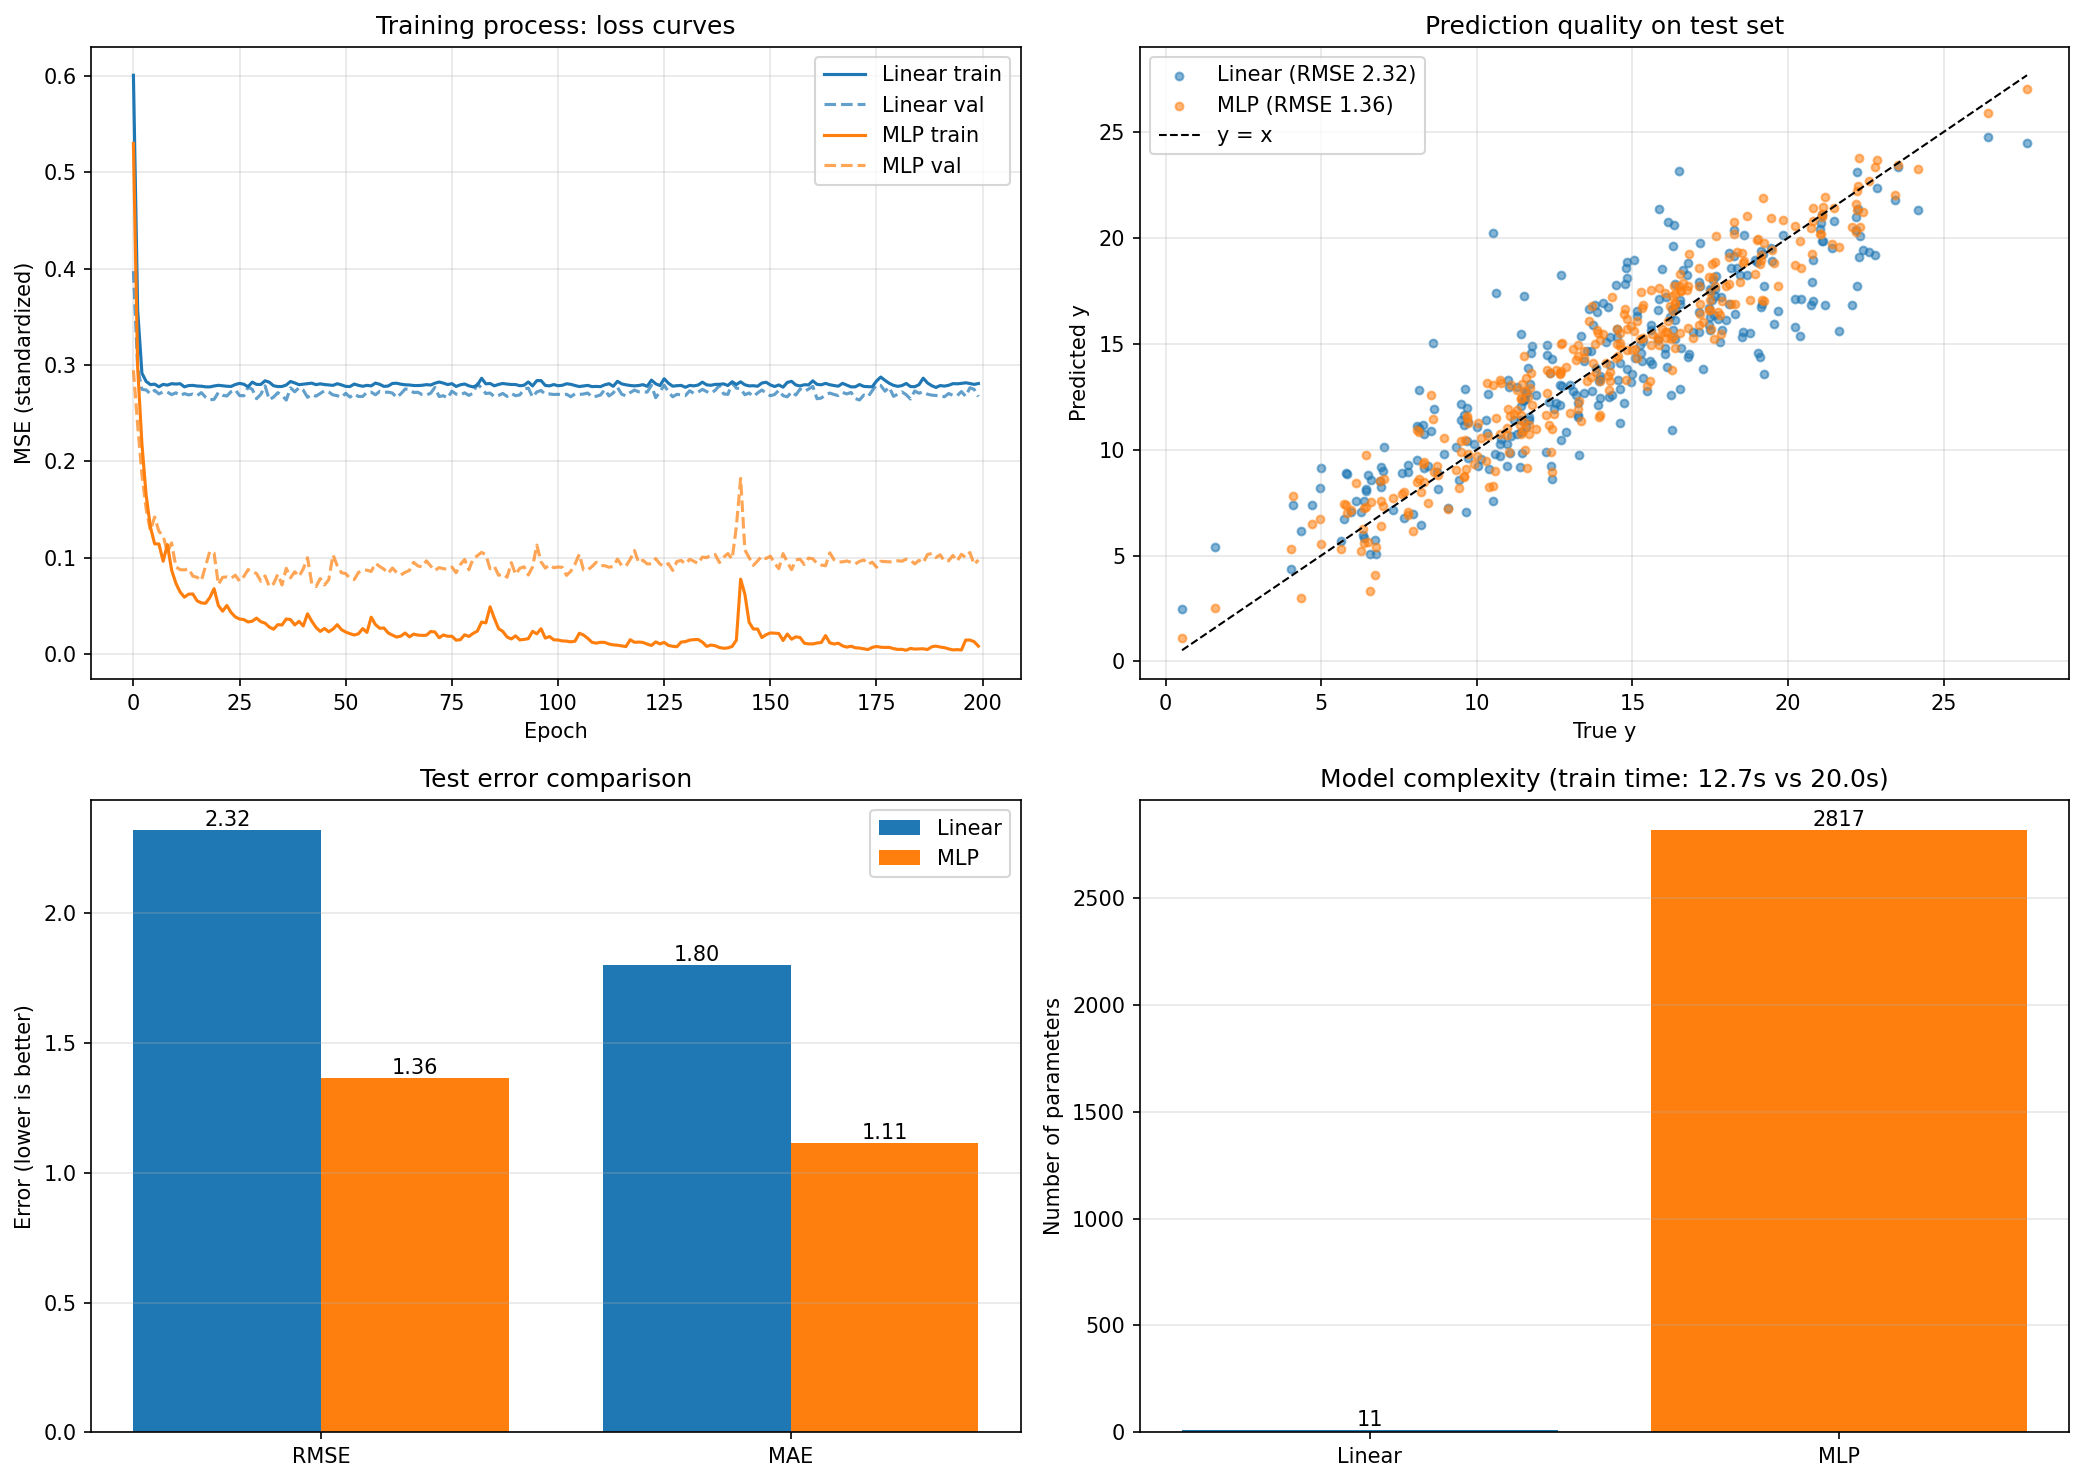

In [17]:
# 2.2-(5) 对比可视化：(a) loss 曲线 (b) 预测 vs 真实 (c) 指标柱状 (d) 参数量 / 耗时
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(lin_train_hist, label="Linear train", color="tab:blue")
axes[0, 0].plot(lin_val_hist, label="Linear val", color="tab:blue", linestyle="--", alpha=0.7)
axes[0, 0].plot(mlp_train_hist, label="MLP train", color="tab:orange")
axes[0, 0].plot(mlp_val_hist, label="MLP val", color="tab:orange", linestyle="--", alpha=0.7)
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("MSE (standardized)")
axes[0, 0].set_title("Training process: loss curves")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

lim = [y_test.min(), y_test.max()]
axes[0, 1].scatter(y_test, lin_pred_test, s=14, alpha=0.55, label="Linear (RMSE %.2f)" % lin_m["RMSE"])
axes[0, 1].scatter(y_test, mlp_pred_test, s=14, alpha=0.55, label="MLP (RMSE %.2f)" % mlp_m["RMSE"])
axes[0, 1].plot(lim, lim, "k--", linewidth=1, label="y = x")
axes[0, 1].set_xlabel("True y")
axes[0, 1].set_ylabel("Predicted y")
axes[0, 1].set_title("Prediction quality on test set")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

metrics = ["RMSE", "MAE"]
xpos = np.arange(len(metrics))
axes[1, 0].bar(xpos - 0.2, [lin_m[k] for k in metrics], width=0.4, label="Linear")
axes[1, 0].bar(xpos + 0.2, [mlp_m[k] for k in metrics], width=0.4, label="MLP")
axes[1, 0].set_xticks(xpos)
axes[1, 0].set_xticklabels(metrics)
axes[1, 0].set_ylabel("Error (lower is better)")
axes[1, 0].set_title("Test error comparison")
for i, k in enumerate(metrics):
    axes[1, 0].text(i - 0.2, lin_m[k], "%.2f" % lin_m[k], ha="center", va="bottom")
    axes[1, 0].text(i + 0.2, mlp_m[k], "%.2f" % mlp_m[k], ha="center", va="bottom")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3, axis="y")

n_lin = sum(p.numel() for p in lin_model.parameters())
n_mlp = sum(p.numel() for p in mlp_model.parameters())
axes[1, 1].bar(["Linear", "MLP"], [n_lin, n_mlp], color=["tab:blue", "tab:orange"])
axes[1, 1].set_ylabel("Number of parameters")
axes[1, 1].set_title("Model complexity (train time: %.1fs vs %.1fs)" % (lin_time, mlp_time))
for i, v in enumerate([n_lin, n_mlp]):
    axes[1, 1].text(i, v, str(v), ha="center", va="bottom")
axes[1, 1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("q2_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("对比图已保存为 q2_model_comparison.png")


## 延伸思考 1：自己设计几种网络结构

在 2.2 的基础上再设计 5 种不同结构的全连接网络，数据与训练配置保持一致，只改网络结构（深度 / 宽度 / 激活函数），比较测试结果。

In [18]:
# 延伸思考 1：5 种不同结构的 MLP 对比（数据与训练配置一致，只改网络结构）
def build_mlp(hidden_dims, activation="relu"):
    act = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}[activation]
    layers = []
    prev = X.shape[1]
    for h in hidden_dims:
        layers += [nn.Linear(prev, h), act()]
        prev = h
    layers.append(nn.Linear(prev, 1))
    return nn.Sequential(*layers)


STRUCTURES = [
    ("A 1层-窄(32)-ReLU", [32], "relu"),
    ("B 2层(64,32)-ReLU（2.2基线）", [64, 32], "relu"),
    ("C 3层(128,64,32)-ReLU", [128, 64, 32], "relu"),
    ("D 2层(256,256)-宽-ReLU", [256, 256], "relu"),
    ("E 3层(64,64,64)-Tanh", [64, 64, 64], "tanh"),
]

struct_rows = []
for name, dims, act_name in STRUCTURES:
    m = build_mlp(dims, act_name)
    n_param = sum(p.numel() for p in m.parameters())
    print("训练 %s …（参数量 %d）" % (name, n_param))
    el, tr_hist, val_hist, best_val = train_model(m, epochs=200, log_every=0)

    pred_test = predict_original(m, X_test_t)
    pred_train = predict_original(m, X_train_t)
    te = regression_metrics(y_test, pred_test, name)
    tr = regression_metrics(y_train, pred_train, name)

    struct_rows.append({
        "结构": name,
        "隐藏层": str(dims),
        "激活": act_name,
        "参数量": n_param,
        "训练耗时(s)": round(el, 2),
        "训练集 RMSE": round(tr["RMSE"], 4),
        "测试集 RMSE": round(te["RMSE"], 4),
        "测试集 R2": round(te["R2"], 4),
        "最优验证MSE": round(min(val_hist), 4),
    })

struct_table = pd.DataFrame(struct_rows)
print("\n================ 不同网络结构对比 ================")
print(struct_table.to_string(index=False))
struct_table.to_csv("q2_structure_experiment.csv", index=False, encoding="utf-8-sig")

best_row = struct_table.loc[struct_table["测试集 RMSE"].idxmin()]
print("\n测试集 RMSE 最小：%s（RMSE=%.4f，R2=%.4f）"
      % (best_row["结构"], best_row["测试集 RMSE"], best_row["测试集 R2"]))
print("参数量最多：%s（%d 个参数）"
      % (struct_table.loc[struct_table["参数量"].idxmax(), "结构"],
         struct_table["参数量"].max()))


训练 A 1层-窄(32)-ReLU …（参数量 385）
训练 B 2层(64,32)-ReLU（2.2基线） …（参数量 2817）
训练 C 3层(128,64,32)-ReLU …（参数量 11777）
训练 D 2层(256,256)-宽-ReLU …（参数量 68865）
训练 E 3层(64,64,64)-Tanh …（参数量 9089）

================ 不同网络结构对比 ================
                     结构           隐藏层   激活   参数量  训练耗时(s)  训练集 RMSE  测试集 RMSE  测试集 R2  最优验证MSE
        A 1层-窄(32)-ReLU          [32] relu   385    14.34    0.9019    1.2992  0.9276   0.0585
B 2层(64,32)-ReLU（2.2基线）      [64, 32] relu  2817    20.18    0.7298    1.3843  0.9178   0.0765
   C 3层(128,64,32)-ReLU [128, 64, 32] relu 11777    15.42    0.9172    1.3544  0.9213   0.0646
   D 2层(256,256)-宽-ReLU    [256, 256] relu 68865    20.82    0.7626    1.3019  0.9273   0.0666
    E 3层(64,64,64)-Tanh  [64, 64, 64] tanh  9089    27.53    1.1207    1.3623  0.9204   0.0757

测试集 RMSE 最小：A 1层-窄(32)-ReLU（RMSE=1.2992，R2=0.9276）
参数量最多：D 2层(256,256)-宽-ReLU（68865 个参数）


结构对比图已保存为 q2_structure_experiment.png


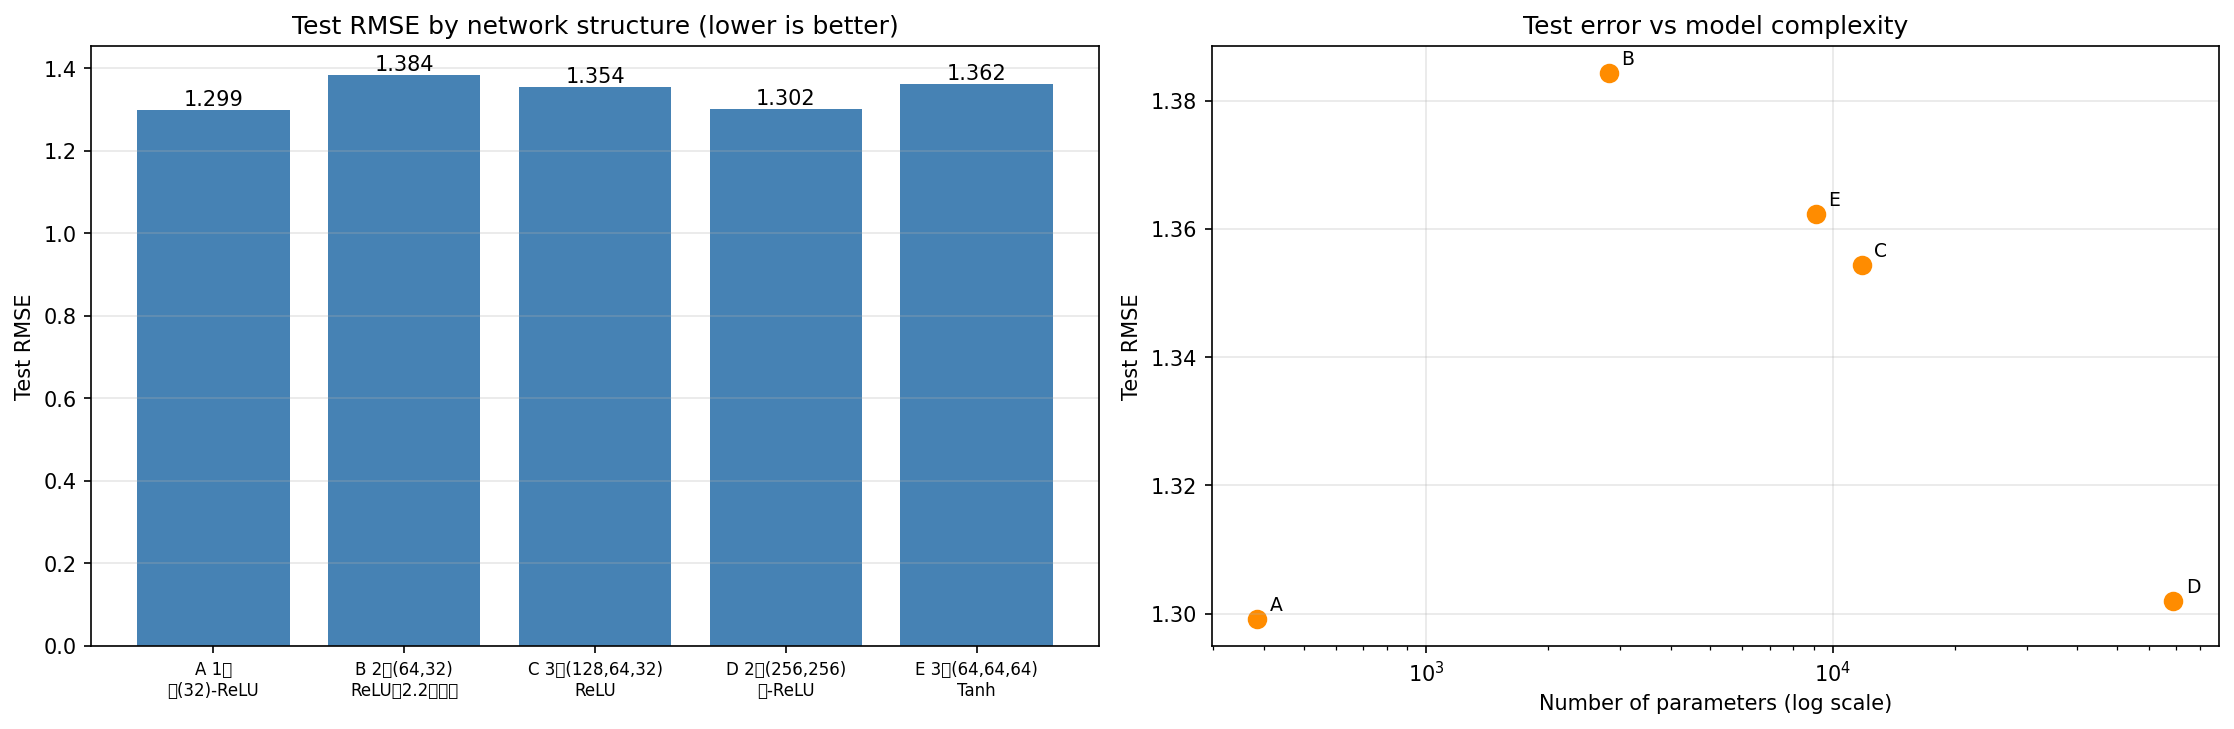

In [19]:
# 延伸思考 1 可视化：不同结构的误差与复杂度
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

names = ["\n".join(n.split("-", 1)) for n in struct_table["结构"]]
axes[0].bar(names, struct_table["测试集 RMSE"], color="steelblue")
axes[0].set_ylabel("Test RMSE")
axes[0].set_title("Test RMSE by network structure (lower is better)")
for i, v in enumerate(struct_table["测试集 RMSE"]):
    axes[0].text(i, v, "%.3f" % v, ha="center", va="bottom")
axes[0].grid(alpha=0.3, axis="y")
axes[0].tick_params(axis="x", labelsize=8)

axes[1].scatter(struct_table["参数量"], struct_table["测试集 RMSE"], s=70, color="darkorange")
for _, r in struct_table.iterrows():
    axes[1].annotate(r["结构"].split()[0], (r["参数量"], r["测试集 RMSE"]),
                     textcoords="offset points", xytext=(6, 4), fontsize=9)
axes[1].set_xlabel("Number of parameters (log scale)")
axes[1].set_ylabel("Test RMSE")
axes[1].set_xscale("log")
axes[1].set_title("Test error vs model complexity")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("q2_structure_experiment.png", dpi=150, bbox_inches="tight")
plt.show()
print("结构对比图已保存为 q2_structure_experiment.png")


## 延伸思考 2：噪声对模型的影响

取 5 个不同的 `noise` 值重新生成数据（`random_state` 固定，因此特征 X 完全相同，只有标签 y 上的噪声幅度变化），观察线性模型与 MLP 的误差如何随噪声变化。

In [20]:
# 延伸思考 2：不同 noise 下的线性模型与 MLP 对比
NOISE_LIST = [0.0, 0.5, 1.0, 2.0, 4.0]
NOISE_EPOCHS = 150

noise_rows = []
for nz in NOISE_LIST:
    Xn, yn = make_friedman1(n_samples=1500, n_features=10, noise=nz, random_state=42)
    Xtr, Xtmp, ytr, ytmp = train_test_split(Xn, yn, test_size=0.4, random_state=SEED)
    Xva, Xte, yva, yte = train_test_split(Xtmp, ytmp, test_size=0.5, random_state=SEED)

    xs = StandardScaler().fit(Xtr)
    ys = StandardScaler().fit(ytr.reshape(-1, 1))

    Xtr_t = to_tensor(xs.transform(Xtr))
    Xva_t = to_tensor(xs.transform(Xva))
    Xte_t = to_tensor(xs.transform(Xte))
    ytr_t = to_tensor(ys.transform(ytr.reshape(-1, 1)))
    yva_t = to_tensor(ys.transform(yva.reshape(-1, 1)))

    def train_quick(model):
        torch.manual_seed(SEED)
        loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=64, shuffle=True)
        crit = nn.MSELoss()
        opt = torch.optim.Adam(model.parameters(), lr=0.01)
        best_val, best_state = float("inf"), None
        for _ in range(NOISE_EPOCHS):
            model.train()
            for xb, yb in loader:
                opt.zero_grad()
                loss = crit(model(xb), yb)
                loss.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                vl = crit(model(Xva_t), yva_t).item()
            if vl < best_val:
                best_val = vl
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            pred = ys.inverse_transform(model(Xte_t).numpy()).ravel()
        return mean_squared_error(yte, pred) ** 0.5, r2_score(yte, pred)

    lin_n = LinearRegressor(10)
    mlp_n = MLPRegressor(10)
    lin_rmse, lin_r2 = train_quick(lin_n)
    mlp_rmse, mlp_r2 = train_quick(mlp_n)

    noise_rows.append({
        "noise": nz,
        "y标准差": round(yte.std(), 3),
        "线性模型 RMSE": round(lin_rmse, 4),
        "线性模型 R2": round(lin_r2, 4),
        "MLP RMSE": round(mlp_rmse, 4),
        "MLP R2": round(mlp_r2, 4),
        "MLP相对线性改善": round(lin_rmse - mlp_rmse, 4),
    })
    print("noise=%.1f 线性 RMSE=%.4f (R2=%.4f) | MLP RMSE=%.4f (R2=%.4f)"
          % (nz, lin_rmse, lin_r2, mlp_rmse, mlp_r2))

noise_table = pd.DataFrame(noise_rows)
print("\n================ 不同噪声水平下的模型表现 ================")
print(noise_table.to_string(index=False))
noise_table.to_csv("q2_noise_experiment.csv", index=False, encoding="utf-8-sig")


noise=0.0 线性 RMSE=2.1603 (R2=0.7863) | MLP RMSE=0.4298 (R2=0.9915)
noise=0.5 线性 RMSE=2.1844 (R2=0.7863) | MLP RMSE=0.8695 (R2=0.9661)
noise=1.0 线性 RMSE=2.3194 (R2=0.7692) | MLP RMSE=1.3638 (R2=0.9202)
noise=2.0 线性 RMSE=2.8719 (R2=0.6924) | MLP RMSE=2.3110 (R2=0.8008)
noise=4.0 线性 RMSE=4.4882 (R2=0.4951) | MLP RMSE=4.4147 (R2=0.5115)

================ 不同噪声水平下的模型表现 ================
 noise  y标准差  线性模型 RMSE  线性模型 R2  MLP RMSE  MLP R2  MLP相对线性改善
   0.0 4.673     2.1603   0.7863    0.4298  0.9915     1.7305
   0.5 4.725     2.1844   0.7863    0.8695  0.9661     1.3149
   1.0 4.828     2.3194   0.7692    1.3638  0.9202     0.9556
   2.0 5.178     2.8719   0.6924    2.3110  0.8008     0.5610
   4.0 6.316     4.4882   0.4951    4.4147  0.5115     0.0735


噪声实验图已保存为 q2_noise_experiment.png


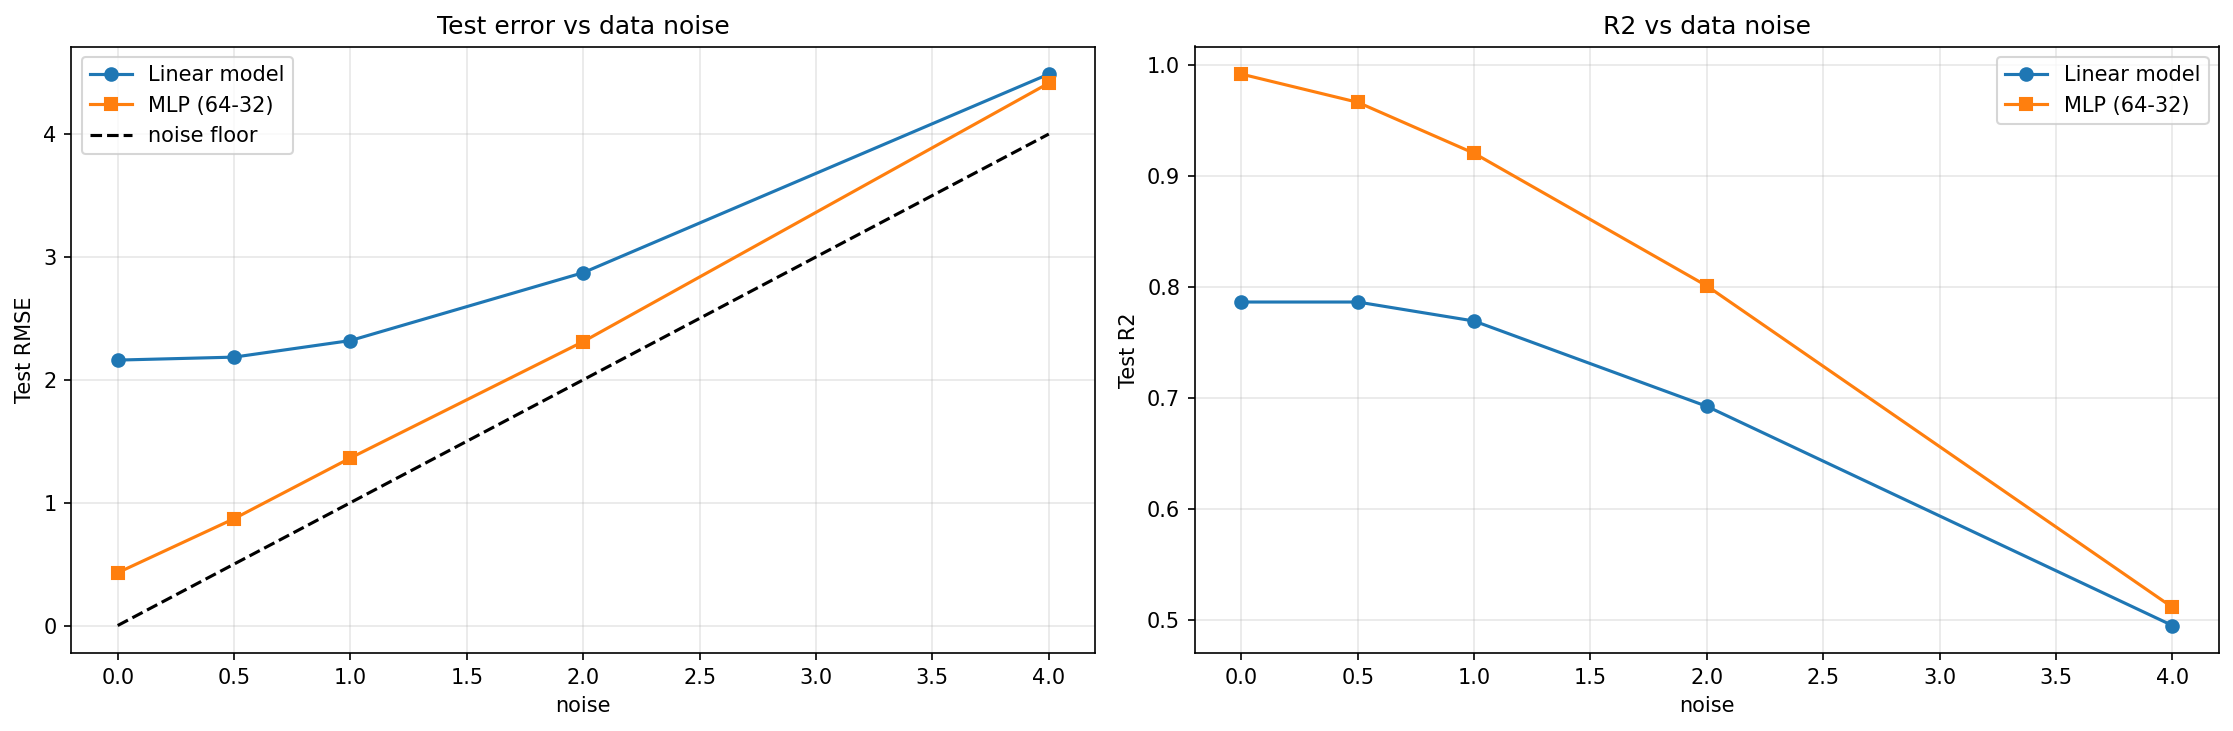

In [21]:
# 延伸思考 2 可视化：性能随噪声的变化
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(noise_table["noise"], noise_table["线性模型 RMSE"], "o-", label="Linear model")
axes[0].plot(noise_table["noise"], noise_table["MLP RMSE"], "s-", label="MLP (64-32)")
axes[0].plot(noise_table["noise"], noise_table["noise"], "k--", label="noise floor")
axes[0].set_xlabel("noise")
axes[0].set_ylabel("Test RMSE")
axes[0].set_title("Test error vs data noise")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(noise_table["noise"], noise_table["线性模型 R2"], "o-", label="Linear model")
axes[1].plot(noise_table["noise"], noise_table["MLP R2"], "s-", label="MLP (64-32)")
axes[1].set_xlabel("noise")
axes[1].set_ylabel("Test R2")
axes[1].set_title("R2 vs data noise")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("q2_noise_experiment.png", dpi=150, bbox_inches="tight")
plt.show()
print("噪声实验图已保存为 q2_noise_experiment.png")


延伸思考 1、2 的具体结果与分析见 `2.2_实验报告.md` 的附录部分。